# K-Nearest Neighbors

This notebook classifies each *province* into a policy class (INCREASE, RETAIN or DECREASE), using the k nearest provinces.
The classes are from the labeled dataset `province_policy_results.csv`, which is created by `methods/label_data.py` from the policies in the Policy for Labeling Data section of the project document.
To check how well it works, we use **k-fold cross validation**.

In [13]:
from pathlib import Path
from models.knearest import *

### Settings

In [14]:
folds = 5        
k = 4          
p = 2           

### Step 1: Read, clean up and standardize the dataset, then get the classes

In [15]:
current_dir_parent = Path.cwd().parent
data_set_dir = getDatasetDir()  
labels_dir = getLabelsDir()
provinces, featuresList, labelList = prepareData(data_set_dir, labels_dir)

print(len(provinces), "provinces,", len(featuresList[0]), "features")
print("True Classes:", labelList)

87 provinces, 12 features
True Classes: [-1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, -1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1]


### Step 1.1: Visualize the true classes in 3D
- The distance uses all 12 fields, but a plot can only show three, so three selected features are used as the x, y and z dimensions
- Change `selected_features` to the indexes of the fields to plot
- Each point is a province, and its color is its true class (red for INCREASE, blue for DECREASE, gray for RETAIN)

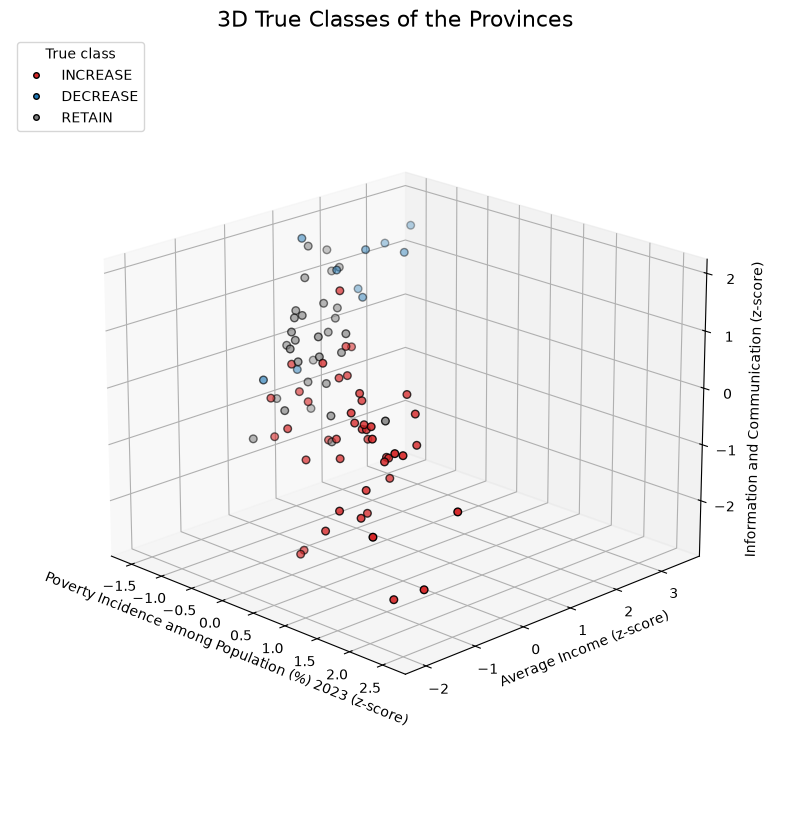

In [16]:
import matplotlib.pyplot as plt

# Indexes of the three fields to use as the x, y and z dimensions
selected_features = [0, 6, 8]     # Poverty Incidence 2023, Average Income, Information and Communication
fields = createMatrix(Path(data_set_dir))[1]      # Names of the fields, for the axis labels

# Color of each class, and the name of each class value (1 = INCREASE, 0 = RETAIN, -1 = DECREASE)
class_colors = {"INCREASE": "tab:red", "DECREASE": "tab:blue", "RETAIN": "tab:gray"}
class_names = {value: name for name, value in CLASS_VALUES.items()}

# Create the 3D Matplotlib Plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')  # Enable 3D projection

# Extract the coordinates of each province from the selected features
x_coords = [p[selected_features[0]] for p in featuresList]
y_coords = [p[selected_features[1]] for p in featuresList]
z_coords = [p[selected_features[2]] for p in featuresList]

# Scatter plot for the data points, colored by the true class of the province
ax.scatter(x_coords, y_coords, z_coords,
           c=[class_colors[class_names[label]] for label in labelList],
           s=30, alpha=1, edgecolor='k')

# Formatting and Titles
# The values are standardized (z-score), since those are the values used for the distance
ax.set_title("3D True Classes of the Provinces", fontsize=16)
ax.set_xlabel(fields[selected_features[0]].split(" | ")[-1] + " (z-score)")
ax.set_ylabel(fields[selected_features[1]].split(" | ")[-1] + " (z-score)")
ax.set_zlabel(fields[selected_features[2]].split(" | ")[-1] + " (z-score)")

# Legend with one entry per class
handles = [plt.Line2D([], [], marker='.', linestyle='', color=color, markeredgecolor='k', markersize=8) for color in class_colors.values()]
ax.legend(handles, list(class_colors.keys()), title="True class", loc="upper left")
ax.set_box_aspect(None, zoom=0.85)     # Zoom out a bit so the z-axis label is not cut off

# Adjust the viewing angle (elevation, azimuth)
ax.view_init(elev=20, azim=-45)

plt.show()

### Step 2: Store the folds

In [17]:
foldList = kFoldSplit(len(featuresList), folds)
printFolds(provinces, foldList)

Fold 1: Bohol, Abra, Aklan, Zamboanga del Sur, Zamboanga del Norte, Sultan Kudarat, Isabela, Ilocos Sur, Quirino, Nueva Ecija, Surigao del Norte, Cavite, Davao Occidental, South Cotabato, Dinagat Islands, Bukidnon, Samar, Cotabato
Fold 2: Basilan, Zambales, Sulu, Sarangani, Agusan del Norte, Mt. Province, Tawi-tawi, Benguet, Davao del Sur, Cebu, Batanes, Davao del Norte, Davao Oriental, Masbate, NCR 1st District, La Union, Camiguin, Nueva Vizcaya
Fold 3: Bataan, Cotabato City, Apayao, Biliran, Rizal, Albay, Bulacan, Negros Occidental, Capiz, Romblon, Oriental Mindoro, Antique, Sorsogon, Pangasinan, Northern Samar, Batangas, Cagayan
Fold 4: Camarines Norte, Aurora, Lanao del Norte, Pampanga, Lanao del Sur, Maguindanao, Ifugao, Agusan del Sur, Davao de Oro, Marinduque, NCR 2nd District, Tarlac, Misamis Occidental, Quezon, Siquijor, Negros Oriental, Occidental Mindoro
Fold 5: Surigao del Sur, Guimaras, Ilocos Norte, Catanduanes, Isabela City, Camarines Sur, Misamis Oriental, Eastern Samar

### Step 3: Evaluate
### K-nearest neighbor with cross validation
`/` means the predicted class is the same as the true class, `x` means it is not.

In [18]:
results = crossValidation(featuresList, labelList, foldList, k, p)
printOutput(k, p, provinces, labelList, results)
printAccuracy(results)

K-Nearest Neighbor Output from the provinces
k: 4	p: 2
class: 1 = INCREASE, 0 = RETAIN, -1 = DECREASE


Province              Fold  True     KNN      Nearest provinces
NCR 1st District      2     -1       -1    /  NCR 2nd District (-1), Pampanga (0), NCR 4th District (-1), Ilocos Norte (0)
NCR 2nd District      4     -1       -1    /  NCR 4th District (-1), NCR 1st District (-1), Rizal (-1), Laguna (-1)
NCR 3rd District      5     -1       0     x  Pampanga (0), Tarlac (0), Benguet (0), Batangas (-1)
NCR 4th District      5     -1       -1    /  NCR 2nd District (-1), NCR 1st District (-1), Rizal (-1), Pampanga (0)
Abra                  1     0        1     x  Marinduque (1), Nueva Vizcaya (0), Southern Leyte (1), Quezon (-1)
Apayao                3     0        0     /  Siquijor (-1), Kalinga (0), Camiguin (0), Ifugao (0)
Benguet               2     0        0     /  Ilocos Norte (0), NCR 3rd District (-1), Batangas (-1), Ilocos Sur (0)
Ifugao                4     0        0     /  Ca


### K-nearest neighbor with confusion matrix


In [19]:
printConfMatrix(results)

Confusion Matrix (Positive class: -1)
                      Predicted    
                  Positive Negative
Actual    Positive       6        4
          Negative       2       75
Recall:    0.6000
Precision: 0.7500
F1 Score:  0.6667
Accuracy:  0.9310

Confusion Matrix (Positive class: 0)
                      Predicted    
                  Positive Negative
Actual    Positive      20       11
          Negative      11       45
Recall:    0.6452
Precision: 0.6452
F1 Score:  0.6452
Accuracy:  0.7471

Confusion Matrix (Positive class: 1)
                      Predicted    
                  Positive Negative
Actual    Positive      39        7
          Negative       9       32
Recall:    0.8478
Precision: 0.8125
F1 Score:  0.8298
Accuracy:  0.8161



{-1: {'matrix': {'TP': 6, 'FN': 4, 'FP': 2, 'TN': 75},
  'recall': 0.6,
  'precision': 0.75,
  'f1_score': 0.6666666666666665,
  'accuracy': 0.9310344827586207},
 0: {'matrix': {'TP': 20, 'FN': 11, 'FP': 11, 'TN': 45},
  'recall': 0.6451612903225806,
  'precision': 0.6451612903225806,
  'f1_score': 0.6451612903225806,
  'accuracy': 0.7471264367816092},
 1: {'matrix': {'TP': 39, 'FN': 7, 'FP': 9, 'TN': 32},
  'recall': 0.8478260869565217,
  'precision': 0.8125,
  'f1_score': 0.8297872340425533,
  'accuracy': 0.8160919540229885}}

### Holdout Validation

In [20]:
printHoldout(featuresList, labelList, provinces, 0.8, k, p)

K-Nearest Neighbor Output from the provinces (holdout)
k: 4	p: 2	train ratio: 0.8
class: 1 = INCREASE, 0 = RETAIN, -1 = DECREASE
only the test provinces are shown, the other provinces were used for training


Province              True     KNN   
NCR 1st District      -1       -1    /
NCR 4th District      -1       -1    /
Kalinga               0        0     /
La Union              0        0     /
Cagayan               0        0     /
Nueva Vizcaya         0        0     /
Batangas              -1       0     x
Occidental Mindoro    1        1     /
Negros Oriental       0        1     x
Siquijor              -1       0     x
Northern Samar        1        1     /
Samar                 1        1     /
Zamboanga Sibugay     1        1     /
Bukidnon              1        1     /
Camiguin              0        1     x
Cotabato              1        1     /
Dinagat Islands       1        1     /


### Holdout Validation with accuracy and confusion matrix
- The same split as above, 80% of the provinces for training and 20% for testing
- The confusion matrix only counts the testing provinces

In [21]:
holdout_results = runHoldout(featuresList, labelList, 0.8, k, p)

holdout_metrics = printConfMatrix(holdout_results)
printAccuracy(holdout_results)

Confusion Matrix (Positive class: -1)
                      Predicted    
                  Positive Negative
Actual    Positive       2        2
          Negative       0       13
Recall:    0.5000
Precision: 1.0000
F1 Score:  0.6667
Accuracy:  0.8824

Confusion Matrix (Positive class: 0)
                      Predicted    
                  Positive Negative
Actual    Positive       4        2
          Negative       2        9
Recall:    0.6667
Precision: 0.6667
F1 Score:  0.6667
Accuracy:  0.7647

Confusion Matrix (Positive class: 1)
                      Predicted    
                  Positive Negative
Actual    Positive       7        0
          Negative       2        8
Recall:    1.0000
Precision: 0.7778
F1 Score:  0.8750
Accuracy:  0.8824


Accuracy: 0.7647


### Visualize the training points of the holdout validation in 3D
- This is the same plot as in Step 1.1, with the same selected features and points
- The large points are the training provinces (80%), and their color is their true class
- The small points are the testing provinces (20%), and their color is the class predicted by KNN from the nearest training points

/tmp/ipykernel_34056/1611698869.py:18: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter([x_coords[i] for i in training],


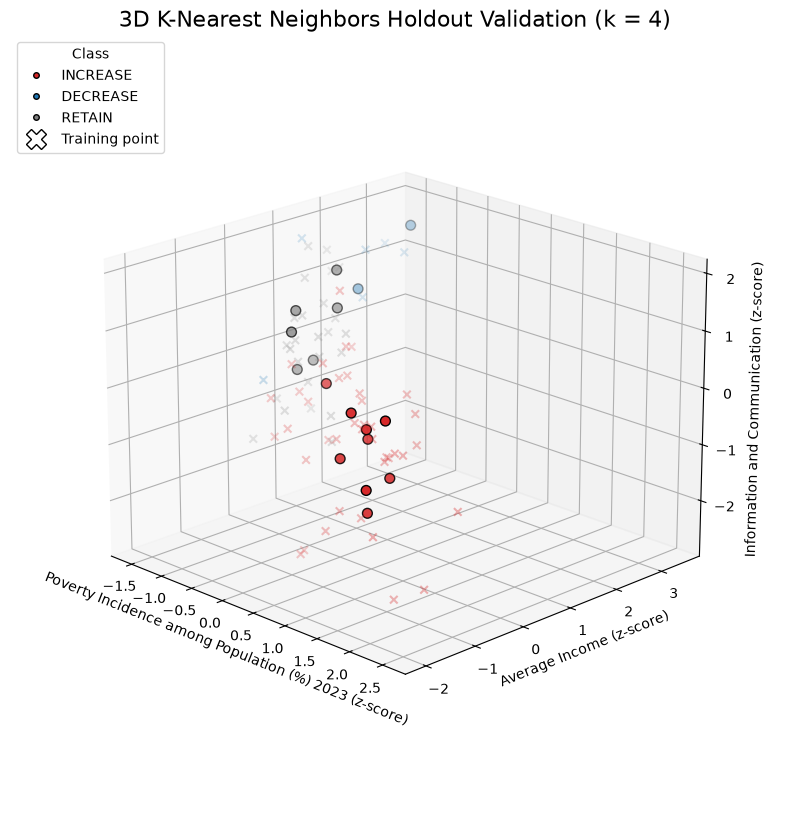

In [32]:
# Create the 3D Matplotlib Plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')  # Enable 3D projection

# Each result is a tuple (province index, true class, predicted class, fold), only for the testing provinces
# The provinces that are not in the results are the training provinces
testing = [result[0] for result in holdout_results]
training = [i for i in range(len(provinces)) if i not in testing]

# Testing points, colored by the class predicted by KNN
ax.scatter([x_coords[i] for i in testing],
           [y_coords[i] for i in testing],
           [z_coords[i] for i in testing],
           c=[class_colors[class_names[result[2]]] for result in holdout_results],
           s=50, alpha=1, edgecolor='k')

# Highlight the training points, colored by their true class
ax.scatter([x_coords[i] for i in training],
           [y_coords[i] for i in training],
           [z_coords[i] for i in training],
           c=[class_colors[class_names[labelList[i]]] for i in training],
           marker='x', s=30, alpha=0.6, edgecolor='k')

# Formatting and Titles
ax.set_title(f"3D K-Nearest Neighbors Holdout Validation (k = {k})", fontsize=16)
ax.set_xlabel(fields[selected_features[0]].split(" | ")[-1] + " (z-score)")
ax.set_ylabel(fields[selected_features[1]].split(" | ")[-1] + " (z-score)")
ax.set_zlabel(fields[selected_features[2]].split(" | ")[-1] + " (z-score)")

# Legend with one entry per class, and one for the highlighted marker
handles = [plt.Line2D([], [], marker='.', linestyle='', color=color, markeredgecolor='k', markersize=8) for color in class_colors.values()]
handles.append(plt.Line2D([], [], marker='X', linestyle='', color='w', markeredgecolor='k', markersize=14))
ax.legend(handles, list(class_colors.keys()) + ["Training point"], title="Class", loc="upper left")
ax.set_box_aspect(None, zoom=0.85)     # Zoom out a bit so the z-axis label is not cut off

# Adjust the viewing angle (elevation, azimuth)
ax.view_init(elev=20, azim=-45)

plt.show()

### Fine Tuning

In [24]:
highest_acc = -1
best_k = -1
for i in range(len(provinces)):
    try:
        results = crossValidation(featuresList, labelList, foldList, i, p)
        acc = accuracy(results)
    except:
        continue
    

    if acc > highest_acc:
        highest_acc = acc
        best_k = i

print(f"The best value of k is: {best_k} with accuracy of {highest_acc}")
results = crossValidation(featuresList, labelList, foldList, best_k, p)
printOutput(best_k, p, provinces, labelList, results)



The best value of k is: 8 with accuracy of 0.7586206896551724
K-Nearest Neighbor Output from the provinces
k: 8	p: 2
class: 1 = INCREASE, 0 = RETAIN, -1 = DECREASE


Province              Fold  True     KNN      Nearest provinces
NCR 1st District      2     -1       -1    /  NCR 2nd District (-1), Pampanga (0), NCR 4th District (-1), Ilocos Norte (0), Laguna (-1), Rizal (-1), NCR 3rd District (-1), Tarlac (0)
NCR 2nd District      4     -1       -1    /  NCR 4th District (-1), NCR 1st District (-1), Rizal (-1), Laguna (-1), Ilocos Norte (0), Cavite (-1), NCR 3rd District (-1), Batanes (0)
NCR 3rd District      5     -1       0     x  Pampanga (0), Tarlac (0), Benguet (0), Batangas (-1), Nueva Ecija (0), Bulacan (0), Cavite (-1), Bataan (0)
NCR 4th District      5     -1       -1    /  NCR 2nd District (-1), NCR 1st District (-1), Rizal (-1), Pampanga (0), Cavite (-1), Batanes (0), Batangas (-1), Bataan (0)
Abra                  1     0        0     /  Marinduque (1), Nueva Vizcaya (0),